# 02 - Analysis

Every table and figure below is computed from `data/raw/{core,product}/summary.csv`. The manuscript's values appear only in the final comparison section.

Options:
- `RETRAIN_LINGAM = True` re-runs the bootstrap DirectLiNGAM (`N_SAMPLING = 100`, about 40 minutes) instead of using the original bootstrap outputs stored in `data/lingam/`.
- `INCLUDE_WORKING_TIME = True` is a sensitivity run that also uses `working_time` as a predictor. `working_time` (creation to resolution) always contains `fixing_time`, so it is excluded by default to avoid target leakage.

In [1]:
from pathlib import Path
import importlib
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

PACKAGE_DIR = Path.cwd().resolve()
if not (PACKAGE_DIR / "replicate.py").exists() and (PACKAGE_DIR / "replication" / "replicate.py").exists():
    PACKAGE_DIR = PACKAGE_DIR / "replication"
sys.path.insert(0, str(PACKAGE_DIR))
import replicate
replicate = importlib.reload(replicate)

TABLES_DIR, FIGURES_DIR = replicate.ensure_dirs(replicate.DEFAULT_OUTPUT)
print("Package:", PACKAGE_DIR)
print("Raw data:", replicate.RAW_DIR)
print("Output:", replicate.DEFAULT_OUTPUT)

Package: .
Raw data: ./data/raw
Output: ./output


In [2]:
RETRAIN_LINGAM = False
N_SAMPLING = 100
INCLUDE_WORKING_TIME = False

replicate.set_include_working_time(INCLUDE_WORKING_TIME)
LINGAM_DIR = (replicate.retrain_lingam(replicate.DEFAULT_OUTPUT / "lingam", N_SAMPLING)
              if RETRAIN_LINGAM else replicate.STORED_LINGAM_DIR)
print("LiNGAM bootstrap outputs:", LINGAM_DIR)

LiNGAM bootstrap outputs: ./data/lingam


## Table I - BFT distribution of the analysis subset

In [3]:
display(replicate.step_02_table1(TABLES_DIR))

[table] ./output/tables/table_I_bft_distribution.csv


,Bug Type,Project,Class 1 (<=1d),Class 2 (2-7d),Class 3 (8-30d),Class 4 (>=31d),Total
0,Product,Firefox,278 (25.91%),276 (25.72%),237 (22.09%),282 (26.28%),1073
1,Product,Firefox for iOS,31 (29.25%),32 (30.19%),23 (21.70%),20 (18.87%),106
2,Product,SeaMonkey,553 (29.73%),427 (22.96%),413 (22.20%),467 (25.11%),1860
3,Product,Thunderbird,113 (27.10%),105 (25.18%),75 (17.99%),124 (29.74%),417
4,Product,Total,975 (28.21%),840 (24.31%),748 (21.64%),893 (25.84%),3456
5,Core,Total,"2,392 (24.94%)","2,617 (27.29%)","2,475 (25.81%)","2,106 (21.96%)",9590
6,Total,,"3,367 (25.81%)","3,457 (26.50%)","3,223 (24.70%)","2,999 (22.99%)",13046


## Figures 5 and 6 - LiNGAM causal strength on BFT

[table] ./output/tables/figure_5_causal_strength_core_data.csv
[figure] ./output/figures/figure_5_causal_strength_core.png
[table] ./output/tables/figure_6_causal_strength_product_data.csv
[figure] ./output/figures/figure_6_causal_strength_product.png


### Figure 5 - Core

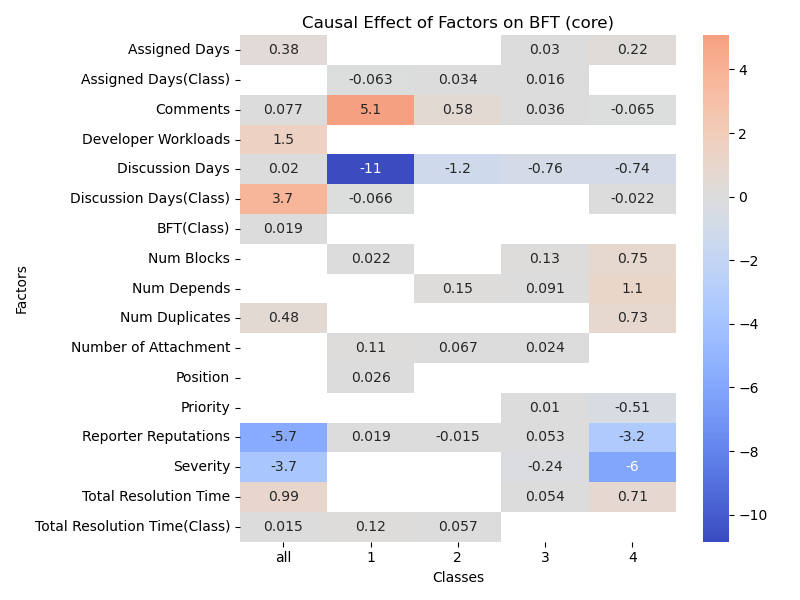

### Figure 6 - Product

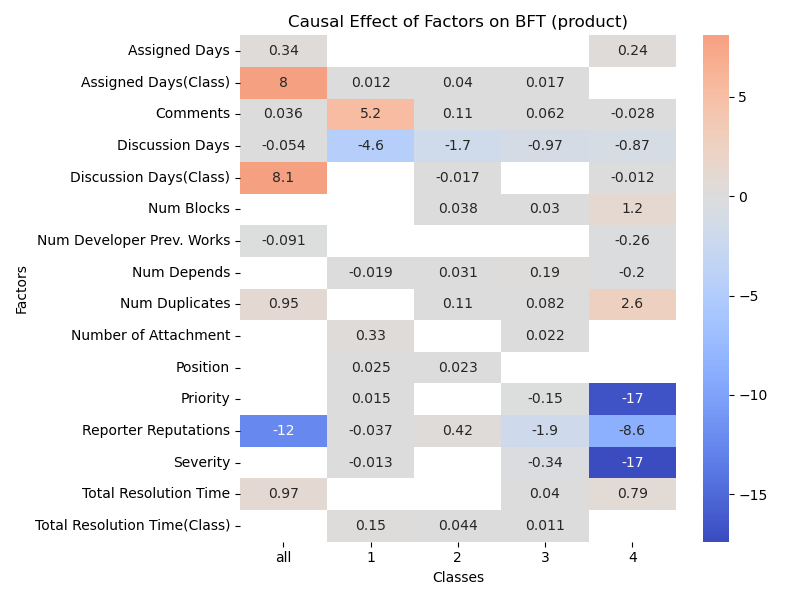

In [4]:
mats = replicate.step_03_heatmaps(TABLES_DIR, FIGURES_DIR, LINGAM_DIR)
display(Markdown("### Figure 5 - Core"))
display(Image(filename=str(FIGURES_DIR / "figure_5_causal_strength_core.png")))
display(Markdown("### Figure 6 - Product"))
display(Image(filename=str(FIGURES_DIR / "figure_6_causal_strength_product.png")))

## Table III - Strength and direction (S > 5, M 1-5, W < 1, N none; Product/Core when they differ)

In [5]:
display(replicate.step_04_table3(TABLES_DIR, LINGAM_DIR))

[table] ./output/tables/table_III_strength_direction.csv


,Related,Factor,Class 1 (<=1d),Class 2 (2-7d),Class 3 (8-30d),Class 4 (>=31d)
0,Long Resolution,Comments,S+,W+,W+,W-
1,Long Resolution,Discussion Days,M-/S-,M-,W-,W-
2,Long Resolution,Number of Attachments,W+,N/W+,W+,N
3,Long Resolution,Position,W+,W+/N,N,N
4,Short Resolution,Assigned Days,N,N,N/W+,W+
5,Short Resolution,Num Depends,W-/N,W+,W+,W-/M+
6,Short Resolution,Num Duplicates,N,W+/N,W+/N,M+/W+
7,Short Resolution,Priority,W+/N,N,W-/W+,S-/W-
8,Short Resolution,Reporter Reputations,W-/W+,W+/W-,M-/W+,S-/M-
9,Short Resolution,Severity,W-/N,N,W-,S-


## Tables IV-VI - RQ3 prediction performance

RF, LR, BN (hill-climbing structure, BDeu) and LiNGAM-BN (LiNGAM edges with bootstrap probability ≥ 0.8 as the BN structure) are trained on a stratified 80/20 split (seed 42). Effect sizes are Cliff's delta against RF, computed over 10 stratified folds of the test set. p-values come from a paired permutation test.

In [6]:
rq3 = replicate.step_05_prediction_tables(TABLES_DIR, LINGAM_DIR)
for name in ["table_IV_performance_product", "table_IV_performance_core", "table_V_macro_f1", "table_VI_effect_size_f1"]:
    display(Markdown(f"### {name}"))
    display(pd.read_csv(TABLES_DIR / f"{name}.csv"))

[rq3] core: train=7,672 test=1,918
[rq3] product: train=2,764 test=692
[table] ./output/tables/table_IV_performance_product.csv
[table] ./output/tables/table_IV_performance_core.csv
[table] ./output/tables/table_V_macro_f1.csv
[table] ./output/tables/table_VI_effect_size_f1.csv


### table_IV_performance_product

,Model,Metric,Class 1 (<=1d),Class 2 (2-7d),Class 3 (8-30d),Class 4 (>=31d)
0,RF,Precision,0.744,0.421,0.360,0.579
1,RF,Recall,0.626,0.458,0.327,0.676
2,RF,F1,0.680,0.439,0.343,0.624
3,LR,Precision,0.488,0.362,0.184,0.486
4,LR,Recall,0.708,0.298,0.060,0.603
5,LR,F1,0.577,0.327,0.090,0.539
6,BN,Precision,0.472,0.475,0.554,0.513
7,BN,Recall,0.728,0.345,0.273,0.559
8,BN,F1,0.573,0.400,0.366,0.535
9,LiNGAM-BN,Precision,0.410,0.389,0.421,0.603


### table_IV_performance_core

,Model,Metric,Class 1 (<=1d),Class 2 (2-7d),Class 3 (8-30d),Class 4 (>=31d)
0,RF,Precision,0.651,0.435,0.449,0.654
1,RF,Recall,0.608,0.516,0.440,0.565
2,RF,F1,0.629,0.472,0.444,0.606
3,LR,Precision,0.444,0.401,0.371,0.602
4,LR,Recall,0.651,0.455,0.261,0.392
5,LR,F1,0.528,0.427,0.306,0.475
6,BN,Precision,0.428,0.381,0.455,0.569
7,BN,Recall,0.622,0.342,0.366,0.477
8,BN,F1,0.507,0.361,0.405,0.519
9,LiNGAM-BN,Precision,0.417,0.360,0.433,0.558


### table_V_macro_f1

,Model,Core,Product
0,RF,0.538,0.521
1,LR,0.434,0.383
2,BN,0.448,0.468
3,LiNGAM-BN,0.430,0.423


### table_VI_effect_size_f1

,Class,Model,Core F1,Core d/p,Product F1,Product d/p
0,Class 1 (<=1d),RF,0.629,--,0.680,--
1,Class 1 (<=1d),LR,0.528,-0.68/0.001,0.577,-0.62/0.001
2,Class 1 (<=1d),BN,0.507,-0.74/0.001,0.573,-0.62/0.001
3,Class 1 (<=1d),LiNGAM-BN,0.484,-0.82/0.001,0.513,-0.79/0.001
4,Class 2 (2-7d),RF,0.472,--,0.439,--
5,Class 2 (2-7d),LR,0.427,-0.58/0.029,0.327,-0.54/0.004
6,Class 2 (2-7d),BN,0.361,-0.82/0.001,0.400,-0.22/0.364
7,Class 2 (2-7d),LiNGAM-BN,0.365,-0.88/0.001,0.366,-0.41/0.096
8,Class 3 (8-30d),RF,0.444,--,0.343,--
9,Class 3 (8-30d),LR,0.306,-0.92/0.001,0.090,-0.86/0.001


## Tables VII-VIII - RQ4 short-duration statistics and binary classification

Table VII describes the BFT of the test reports that LiNGAM-BN predicts as class 1. Table VIII uses the original binary split (Core ≤ 9 days, Product ≤ 4 days) with the 2-class LiNGAM outputs.

In [7]:
replicate.step_06_binary_tables(TABLES_DIR, LINGAM_DIR, rq3)
for name in ["table_VII_short_duration_bft_stats", "table_VIII_binary_accuracy"]:
    display(Markdown(f"### {name}"))
    display(pd.read_csv(TABLES_DIR / f"{name}.csv"))

[table] ./output/tables/table_VII_short_duration_bft_stats.csv
[rq4] core: threshold <= 9d, LiNGAM features=['num_duplicates', 'reporter_reputations', 'assigned_days', 'discussion_days', 'comment_count']
[rq4] product: threshold <= 4d, LiNGAM features=['severity', 'num_duplicates', 'reporter_reputations', 'comment_count']
[table] ./output/tables/table_VIII_binary_accuracy.csv


### table_VII_short_duration_bft_stats

,Metric,Product,Core
0,Count,327.000,665.000
1,Mean,31.758,13.417
2,Std Dev,80.998,32.780
3,Min,0.000,0.000
4,25%,1.000,1.000
5,50%,3.000,2.000
6,75%,16.500,9.000
7,Max,560.000,249.000


### table_VIII_binary_accuracy

,Model,Core Accuracy,Product Accuracy
0,LR,0.6637,0.7341
1,RF,0.7513,0.7905
2,BN,0.7325,0.7254
3,LiNGAM+LR,0.6658,0.6922
4,LiNGAM+RF,0.7112,0.6879
5,LiNGAM+BN,0.7174,0.6965
6,LiNGAM+BN(Multi-class),0.4286,0.4408
7,Majority baseline,0.5699,0.5621


## Computed values vs the manuscript (held-out protocol above)

In [8]:
summary = replicate.step_07_compare_with_paper(TABLES_DIR)
display(summary)
detail = pd.read_csv(TABLES_DIR / "07_paper_vs_computed.csv")
display(detail[~detail["Match"]])

[table] ./output/tables/07_paper_vs_computed.csv
[table] ./output/tables/07_paper_vs_computed_summary.csv


,Artifact,Matched,Total
0,Table I total,7,7
1,Figure 5 (Core),49,49
2,Figure 6 (Product),53,53
3,Table III,40,40
4,Table IV (Product),1,48
5,Table IV (Core),1,48
6,Table V (vs macro-F1),0,8
7,Table VII,0,6
8,Table VIII,0,14


,Artifact,Item,Paper,Computed,Match
149,Table IV (Product),RF Precision class 1,0.87,0.744,False
150,Table IV (Product),RF Precision class 2,0.67,0.421,False
151,Table IV (Product),RF Precision class 3,0.69,0.36,False
152,Table IV (Product),RF Precision class 4,0.81,0.579,False
153,Table IV (Product),LR Precision class 1,0.88,0.488,False
...,...,...,...,...,...
268,Table VIII,Product BN,0.882,0.7254,False
269,Table VIII,Product LiNGAM+LR,0.876,0.6922,False
270,Table VIII,Product LiNGAM+RF,0.873,0.6879,False
271,Table VIII,Product LiNGAM+BN,0.936,0.6965,False


## Paper protocol: the evaluation behind the manuscript's Tables IV-VIII

`paper_protocol.py` re-implements `exec/bn_t.py`, which produced the manuscript's BN and LiNGAM-BN numbers. It uses the same preprocessing, row order and stratified split. The BN is the original saved structure (`data/models/`), because hill-climbing is not exactly deterministic. LiNGAM-BN is re-fitted from the LiNGAM edges with bootstrap probability ≥ 0.8.

This protocol has two conditions the manuscript does not state:
1. **The BNs are fitted on all reports, including the test split.**
2. **`working_time` (creation to resolution, binned at the same 1/7/30-day cut points as BFT) is part of the evidence.**

The diagnostic table below shows each model under all four combinations. No RF/LR code survives, so RF/LR here are the closest reconstruction: the same inputs as the BNs, fitted on the training split.

In [9]:
pp_summary = replicate.step_08_paper_protocol(replicate.DEFAULT_OUTPUT, LINGAM_DIR)
PP_DIR = replicate.DEFAULT_OUTPUT / "paper_protocol" / "tables"
display(pp_summary)
for name in ["table_IV_performance_product", "table_IV_performance_core", "table_V_macro_f1",
             "table_VIII_binary_accuracy", "08_protocol_diagnostics"]:
    display(Markdown(f"### paper protocol: {name}"))
    display(pd.read_csv(PP_DIR / f"{name}.csv"))

[paper protocol] core: done


[paper protocol] product: done
[table] ./output/paper_protocol/tables/table_IV_performance_product.csv
[table] ./output/paper_protocol/tables/table_IV_performance_core.csv
[table] ./output/paper_protocol/tables/table_V_macro_f1.csv
[table] ./output/paper_protocol/tables/table_VI_effect_size_f1.csv
[table] ./output/paper_protocol/tables/table_VII_short_duration_bft_stats.csv
[table] ./output/paper_protocol/tables/table_VIII_binary_accuracy.csv


[table] ./output/paper_protocol/tables/08_protocol_diagnostics.csv
[table] ./output/paper_protocol/tables/07_paper_vs_computed.csv
[table] ./output/paper_protocol/tables/07_paper_vs_computed_summary.csv


,Artifact,Matched,Total
0,Table IV (Product),48,48
1,Table IV (Core),48,48
2,Table V (vs macro-F1),8,8
3,Table V (vs accuracy),8,8
4,Table VII,6,6
5,Table VIII,14,14


### paper protocol: table_IV_performance_product

,Model,Metric,Class 1 (<=1d),Class 2 (2-7d),Class 3 (8-30d),Class 4 (>=31d)
0,RF,Precision,0.866,0.671,0.687,0.811
1,RF,Recall,0.728,0.643,0.760,0.911
2,RF,F1,0.791,0.657,0.722,0.858
3,LR,Precision,0.882,0.640,0.803,0.784
4,LR,Recall,0.692,0.667,0.733,0.994
5,LR,F1,0.776,0.653,0.767,0.877
6,BN,Precision,1.000,0.650,0.812,0.775
7,BN,Recall,0.672,0.762,0.720,1.000
8,BN,F1,0.804,0.701,0.763,0.873
9,LiNGAM-BN,Precision,0.986,0.755,0.776,0.782


... (4 outputs left out)

### paper protocol: table_VIII_binary_accuracy

,Model,Core Accuracy,Product Accuracy
0,LR,0.8608,0.8786
1,RF,0.8452,0.8786
2,BN,0.8608,0.8815
3,LiNGAM+LR,0.8613,0.8757
4,LiNGAM+RF,0.8368,0.8728
5,LiNGAM+BN,0.9124,0.9364
6,LiNGAM+BN(Multi-class),0.8405,0.8165


### paper protocol: 08_protocol_diagnostics

,Scope,Model,BN fitted on,working_time evidence,Accuracy,Macro-F1
0,Core,BN,all reports (incl. test),yes,0.7789,0.778
1,Core,LiNGAM-BN,all reports (incl. test),yes,0.8405,0.842
2,Core,BN,all reports (incl. test),no,0.3707,0.368
3,Core,LiNGAM-BN,all reports (incl. test),no,0.4885,0.488
4,Core,BN,training split,yes,0.7737,0.774
5,Core,LiNGAM-BN,training split,yes,0.7059,0.710
6,Core,BN,training split,no,0.3629,0.360
7,Core,LiNGAM-BN,training split,no,0.3384,0.336
8,Product,BN,all reports (incl. test),yes,0.7890,0.785
9,Product,LiNGAM-BN,all reports (incl. test),yes,0.8165,0.812


In [10]:
pp_detail = pd.read_csv(PP_DIR / "07_paper_vs_computed.csv")
pp_detail["Model"] = pp_detail["Item"].str.split().str[1].where(pp_detail["Artifact"].str.startswith("Table V") | pp_detail["Artifact"].str.startswith("Table VIII"), pp_detail["Item"].str.split().str[0])
display(pp_detail.groupby(["Artifact", "Model"])["Match"].agg(Matched="sum", Total="count"))

Matched  Total
Artifact              Model                                 
Table IV (Core)       BN                           12     12
                      LR                           12     12
                      LiNGAM-BN                    12     12
                      RF                           12     12
Table IV (Product)    BN                           12     12
                      LR                           12     12
                      LiNGAM-BN                    12     12
                      RF                           12     12
Table V (vs accuracy) BN                            2      2
                      LR                            2      2
                      LiNGAM-BN                     2      2
                      RF                            2      2
Table V (vs macro-F1) BN                            2      2
                      LR                            2      2
                      LiNGAM-BN                     2      2
                      RF                            2      2
Table VII             Count                         2      2
                      Max                           2      2
                      Mean                          2      2
Table VIII            BN                            2      2
                      LR                            2      2
                      LiNGAM+BN                     2      2
                      LiNGAM+BN(Multi-class)        2      2
                      LiNGAM+LR                     2      2
                      LiNGAM+RF                     2      2
                      RF                            2      2

## Check against the manuscript

`check_manuscript.py` reads every value printed in the manuscript's tables from `../section/*.tex` and compares it with the computed value, to the printed precision.

In [11]:
import check_manuscript
importlib.reload(check_manuscript)
sys.argv = ["check_manuscript", "--section", str(PACKAGE_DIR.parent / "section")]
check_manuscript.RESULTS.clear()
check_manuscript.main()
check = pd.read_csv(replicate.DEFAULT_OUTPUT / "manuscript_check.csv")
display(check[~check["Match"]])

               Table  Matched  Total
             Table I       63     63
     Figure 5 (Core)       49     49
  Figure 6 (Product)       53     53
           Table III       40     40
   Table IV (P/R/F1)       96     96
  Table V (macro-F1)        8      8
       Table VI (F1)       32     32
Table VI (Cliff's d)       24     24
        Table VI (p)       24     24
           Table VII       16     16
          Table VIII       14     14

All: 419 / 419 printed values reproduced (details: output/manuscript_check.csv)


,Table,Item,Paper,Computed,Source,Match
